In [33]:
from typing import TypedDict , Annotated
from langgraph.graph import StateGraph, START, END ,MessagesState
import wikipediaapi
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langgraph.graph.message import add_messages
import operator
from openai import OpenAI
import os
from langchain_openai import ChatOpenAI
from langchain_core.tools import tool 
from langgraph.prebuilt import ToolNode,tools_condition
from langchain_core.messages import ToolMessage
from IPython.display import Image, display


load_dotenv()
llm = ChatOpenAI(
    model="openai/gpt-oss-20b",
    api_key=os.environ.get("GROQ_API_KEY"),
    base_url="https://api.groq.com/openai/v1",
)


Part 1: Researcher Graph


In [45]:
wiki = wikipediaapi.Wikipedia(user_agent="3 agents_project/1.0 (student@example.com)")
MAX_CHARS_PER_PAGE = 2000

@tool 
def wiki_search(query: str)-> str:
    """Search Wikipedia for a query and return raw text from the top matching pages."""
    results = wiki.search(query, limit=2)
    output = ""
    for title, page in results.pages.items():
        output += f" {title}\n{page.text[:MAX_CHARS_PER_PAGE]}\n\n"
    return output or f"No results found for: {query}"

tools = [wiki_search]
llm_with_tools = llm.bind_tools(tools)


ResearcherState=TypedDict("ResearcherState",{"task":str,"research":str,"messages": Annotated[list, add_messages], "trace": Annotated[list, operator.add]})

def researcher_node(state: ResearcherState) -> dict:
    response = llm_with_tools.invoke([("system", "You are a research agent. You must call the Wikipedia tool to gather information about the task. Do not summarize, rewrite, or format anything. Return raw notes only"), 
                                    ("human", state["task"])] + state["messages"])
    tool_texts = [m.content for m in state["messages"] if isinstance(m, ToolMessage)] 
    if tool_texts:
        research = "\n\n".join(tool_texts)
    else:
        research = state["research"]
    return {"research": research, "messages": [response], "trace": ["researcher"]}

builder = StateGraph(ResearcherState)
builder.add_node("researcher_node", researcher_node)
builder.add_node("research_tools", ToolNode(tools))

builder.add_edge(START,"researcher_node")
builder.add_conditional_edges("researcher_node",tools_condition,{"tools":"research_tools",END:END},)
builder.add_edge("research_tools", "researcher_node")

researcher_app = builder.compile()



Task 5: Run the Researcher Standalone

In [35]:
result = researcher_app.invoke({
    "task": "Research the history of the Python programming language.",
    "research": "",
    "messages": [],
    "trace": [],
})

print("TRACE:", result["trace"])
print("RESEARCH LENGTH:", len(result["research"]))
print("RESEARCH PREVIEW:", result["research"][:500])
print("MESSAGE TYPES:", [type(m).__name__ for m in result["messages"]])

TRACE: ['researcher', 'researcher']
RESEARCH LENGTH: 9100
RESEARCH PREVIEW:  Python (programming language)
Python is a high-level, general-purpose programming language that emphasizes code readability, simplicity, and ease-of-writing with the use of significant indentation, an extensive ("batteries-included") standard library, and garbage collection. Python supports multiple programming paradigms but with an emphasis on object-oriented programming and dynamic typing.
Guido van Rossum began working on Python in the late 1980s as a successor to the ABC programming languag
MESSAGE TYPES: ['AIMessage', 'ToolMessage', 'AIMessage']


Task 6: Visualize the Researcher Graph

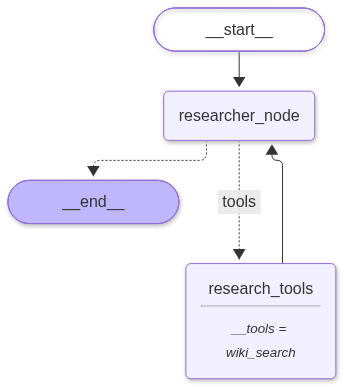

In [36]:
display(Image(researcher_app.get_graph().draw_mermaid_png()))

Part 2: Build the Writer Graph

In [37]:
writerState=TypedDict("writerState",{"task":str,"research":str,"feedback":str,"draft":str,"attempts":int,"messages": Annotated[list, add_messages], "trace": Annotated[list, operator.add]})

def writer_node(state: writerState) -> dict:
    prompt = f"Task: {state['task']}"

    if state["research"]:
        prompt += f"\n\nResearch:\n{state['research']}"

    if state["feedback"]:
        prompt += f"\n\nFeedback:\n{state['feedback']}"

    response = llm.invoke([("system", "You are a writing agent. You must write a draft based on the task, research, and feedback. Do not summarize, rewrite, or format anything. Return raw notes only"),        
                           ("human", prompt)] + state["messages"])

    return {"draft": response.content, "attempts": state["attempts"] + 1,"messages": [response], "trace": ["writer"]}   


builder = StateGraph(writerState)
builder.add_node("writer_node", writer_node)
builder.add_edge(START,"writer_node")
builder.add_edge("writer_node", END)
writer_app = builder.compile()


Task 4: Run the Writer Standalone

In [38]:
result = writer_app.invoke({
    "task": "Write a 3-sentence pitch for a plant-watering mobile app.",
    "research": "",
    "feedback": "",
    "draft": "",
    "attempts": 0,
    "messages": [],
    "trace": []
})

print("draft:",result["draft"])
print("TRACE:", result["trace"])
print("feedback:",result["feedback"])
print("ATTEMPTS:", result["attempts"])
print(result)

draft: Ever feel guilty when your desk fern wilts? Meet GreenThumb, your AI‑powered watering assistant that tracks your plant’s hydration needs, sends real‑time reminders, and suggests optimal care schedules. With a vibrant community, customizable watering reminders, and smart sensor integration, keeping your green space thriving has never been easier.
TRACE: ['writer']
feedback: 
ATTEMPTS: 1
{'task': 'Write a 3-sentence pitch for a plant-watering mobile app.', 'research': '', 'feedback': '', 'draft': 'Ever feel guilty when your desk fern wilts? Meet GreenThumb, your AI‑powered watering assistant that tracks your plant’s hydration needs, sends real‑time reminders, and suggests optimal care schedules. With a vibrant community, customizable watering reminders, and smart sensor integration, keeping your green space thriving has never been easier.', 'attempts': 1, 'messages': [AIMessage(content='Ever feel guilty when your desk fern wilts? Meet GreenThumb, your AI‑powered watering assistant

Task 5: Visualize the Writer Graph

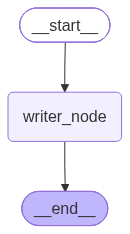

In [39]:
display(Image(writer_app.get_graph().draw_mermaid_png()))

Part 3: Build the Reviewer Graph

In [40]:
from pydantic import BaseModel, Field
from langchain_core.messages import AIMessage
class Review(BaseModel):
    feedback: str = Field(description="Specific, actionable feedback on the draft.")
    approved: bool = Field(description="True if the draft is good enough to publish.")

reviewerState=TypedDict("reviewerState",{"task":str,"feedback":str,"draft":str,"approved":bool,"messages": Annotated[list, add_messages], "trace": Annotated[list, operator.add]})
structured_model= llm.with_structured_output(Review)

def reviewer_node(state: reviewerState) -> dict:
    prompt = ([("system", "You are a strict editor. Judge the draft against the task and every one of its constraints. Approve only if the draft meets all constraints AND is original, vivid, and memorable. Most first drafts need at least one concrete improvement, so give specific changes unless the draft is excellent. Set approved to true only when no further improvement is needed."),        
              ("human", f"Task: {state['task']}\n\nDraft:\n{state['draft']}")])
    review = structured_model.invoke(prompt)
    return {"feedback": review.feedback, "approved": review.approved, "messages": [AIMessage(content=review.feedback)] , "trace": ["reviewer"]}

state_graph = StateGraph(reviewerState)
state_graph.add_node("reviewer_node", reviewer_node)

state_graph.add_edge(START,"reviewer_node")
state_graph.add_edge("reviewer_node", END)

reviewer_app = state_graph.compile()


Task 5: Run the Reviewer Standalone


In [48]:
result = reviewer_app.invoke({"task": "Write a slogan for a coffee shop.",
"draft": "Coffee that wakes you up and keeps you going.",
"feedback": "", "approved": False, "messages": [], "trace": []})

print("task:",result["task"])
print("draft:", result["draft"])
print("feedback:",result["feedback"])
print("approved:", result["approved"])
print("trace:", result["trace"])
print(result)


task: Write a slogan for a coffee shop.
draft: Coffee that wakes you up and keeps you going.
feedback: The slogan is too generic and lacks vivid imagery. Consider focusing on a unique sensory experience or a memorable twist to make it stand out. For example: "Awaken your senses—sip the sunrise in a cup."
approved: False
trace: ['reviewer']
{'task': 'Write a slogan for a coffee shop.', 'feedback': 'The slogan is too generic and lacks vivid imagery. Consider focusing on a unique sensory experience or a memorable twist to make it stand out. For example: "Awaken your senses—sip the sunrise in a cup."', 'draft': 'Coffee that wakes you up and keeps you going.', 'approved': False, 'messages': [AIMessage(content='The slogan is too generic and lacks vivid imagery. Consider focusing on a unique sensory experience or a memorable twist to make it stand out. For example: "Awaken your senses—sip the sunrise in a cup."', additional_kwargs={}, response_metadata={}, id='2743bb30-5f52-4f18-8ba0-65efd01d

Task 6: Visualize the Reviewer Graph

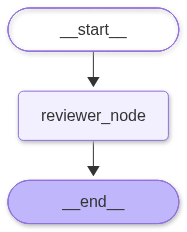

In [42]:
display(Image(reviewer_app.get_graph().draw_mermaid_png()))

Part 4: Build the Orchestration Layer

In [43]:
OrchestratorState=TypedDict("OrchestratorState",{"task":str,"research":str,"draft":str,"feedback":str,"approved":bool,"attempts":int, "trace": Annotated[list, operator.add]})

def run_researcher(state: OrchestratorState) -> dict:
    out = researcher_app.invoke(
    {
        "task": state["task"],
        "research": "",
        "messages": [],
        "trace": [],
    }
    )
    return {
        "research": out["research"],
        "trace": ["researcher"],
    }
def run_writer(state: OrchestratorState) -> dict:
    out = writer_app.invoke(
    {
        "task": state["task"],
        "research": state["research"],
        "feedback": state["feedback"],
        "draft": state["draft"],
        "attempts": state["attempts"],
        "messages": [],
        "trace": [],
    }
    )
    return {
    "draft": out["draft"],
    "attempts": out["attempts"],
    "trace": ["writer"],
    }
def run_reviewer(state: OrchestratorState) -> dict:
    out = reviewer_app.invoke(
    {
        "task": state["task"],
        "draft": state["draft"],
        "feedback": "",
        "approved": False,
        "messages": [],
        "trace": [],
    }
    )
    return {
    "feedback": out["feedback"],
    "approved": out["approved"],
    "trace": ["reviewer"],
    }


MAX_ATTEMPTS = 5

def route_after_review(state: OrchestratorState) -> str:
    if state["approved"] or state["attempts"] >= MAX_ATTEMPTS:
        return END
    return "writer"

Orchestrator_graph = StateGraph(OrchestratorState)
Orchestrator_graph.add_node("researcher", run_researcher)
Orchestrator_graph.add_node("writer", run_writer)
Orchestrator_graph.add_node("reviewer", run_reviewer)

Orchestrator_graph.add_edge(START, "researcher")
Orchestrator_graph.add_edge("researcher", "writer")
Orchestrator_graph.add_edge("writer", "reviewer")
Orchestrator_graph.add_conditional_edges("reviewer", route_after_review, {"writer":"writer", END:END})

multi_agent_app = Orchestrator_graph.compile()

Task 5: Run the Orchestrated Workflow

In [ ]:
result = multi_agent_app.invoke({
    "task": "Write a single-sentence slogan for a coffee shop. Keep it under 10 words.",
    "research": "",
    "draft": "", 
    "feedback": "", 
    "approved": False,
    "attempts": 0, 
    "trace": [],
})

print("TRACE:", result["trace"])
print("ATTEMPTS:", result["attempts"])
print("APPROVED:", result["approved"])
print("DRAFT:", result["draft"])
print("RESEARCH LENGTH:", len(result["research"]))
print("RESEARCH PREVIEW:", result["research"][:3000])

TRACE: ['researcher', 'writer', 'reviewer', 'writer', 'reviewer']
ATTEMPTS: 2
APPROVED: True
DRAFT: Brewed moments, shared smiles—every cup sparks connection.
RESEARCH LENGTH: 2801
RESEARCH PREVIEW:  Coffee shop
Coffee shop may refer to:

Shops and establishments
Coffeehouse or café, an establishment where coffee is served
Coffeeshop (Netherlands), a place where cannabis products are sold and consumed
Coffee shop, in the U.S., a casual, popular-priced restaurant similar to a diner
Kopitiam, a version of the coffee shops common in Singapore and Malaysia
The Coffee Shop (New York City), a defunct American restaurant

Television
Coffee Shop (Urban TV), Ugandan TV series

Music
"Coffee Shop" (B.A.P song)
"Coffee Shop" (Red Hot Chili Peppers song)
"Coffee Shop" (Yung Joc song)
"Coffee Shop Soundtrack", a single by All Time Low

See also
Cafe (disambiguation)
Coffeehouse (disambiguation)
All pages with titles containing coffee shop
All pages with titles containing coffeeshop

 Coffeehouse
A 

Task 4: Assemble & Visualize the Orchestration Graph

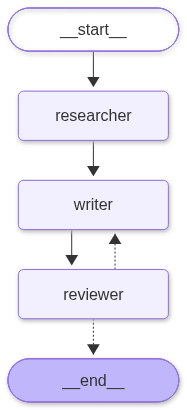

In [ ]:
display(Image(multi_agent_app.get_graph().draw_mermaid_png())) 

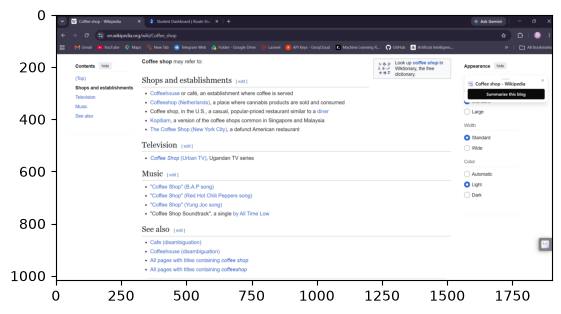

In [ ]:

display(Image(filename="")
